# 02 — Feature Analysis

Explores `data/processed/features.parquet` directly (10,854 rows, one per grid cell) before
the index/hotspot/validation stages consume it. Everything below is computed fresh from the
feature table in this notebook, not copied from `outputs/tables/` — this is exploratory
groundwork, not a re-display of `validation.py`'s already-computed results.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100

df = pd.read_parquet(ROOT / "data" / "processed" / "features.parquet")
land = df[df["land_mask"]]
water = df[~df["land_mask"]]
print(f"total cells: {len(df)}   land cells: {len(land)}   water/excluded cells: {len(water)}")

total cells: 10854   land cells: 5801   water/excluded cells: 5053


## Distributions on land cells

`lst`, `ndvi`, `ndbi`, `built_up` (GHSL), `pop_density` — all restricted to `land_mask` cells,
since that's the analysis universe every later pipeline stage uses.

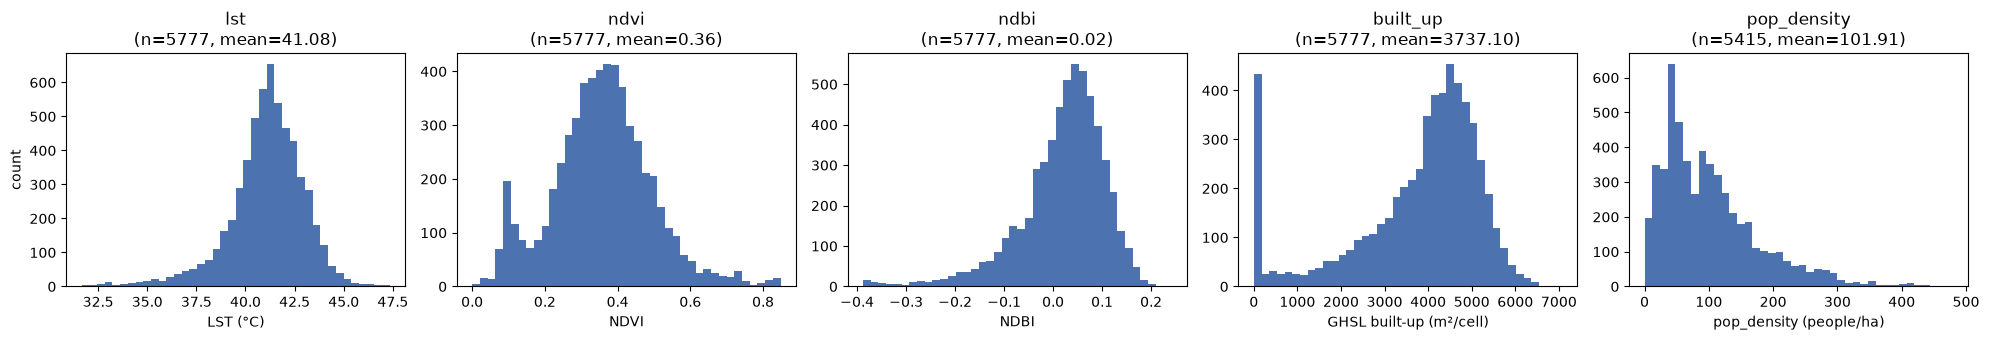

In [2]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
specs = [
    ("lst", "LST (°C)"),
    ("ndvi", "NDVI"),
    ("ndbi", "NDBI"),
    ("built_up", "GHSL built-up (m²/cell)"),
    ("pop_density", "pop_density (people/ha)"),
]
for ax, (col, label) in zip(axes, specs):
    vals = land[col].dropna()
    ax.hist(vals, bins=40, color="#4c72b0", edgecolor="none")
    ax.set_xlabel(label)
    ax.set_title(f"{col}\n(n={len(vals)}, mean={vals.mean():.2f})")
axes[0].set_ylabel("count")
fig.tight_layout()
plt.show()

Notes: `pop_density` is heavily right-skewed (most cells low-density, a long tail of dense
urban cells) — this skew is exactly why `hvi.py`'s HEI ends up skewed too (see
`03_hvi_experiments.ipynb`). `ndvi` and `built_up` both show the expected bimodal-ish shape of
a mixed urban/green landscape.

## Land vs. water LST contrast

This is *the* reason land masking is mandatory in this pipeline: sea-surface LST is valid data
(not nodata), and it sits well below land LST, so leaving water in would drag every land
statistic down.

land-only mean LST:      41.08 degC  (n=5777)
water-only mean LST:     30.29 degC  (n=4903)
combined (land+water):   36.13 degC  (n=10680)


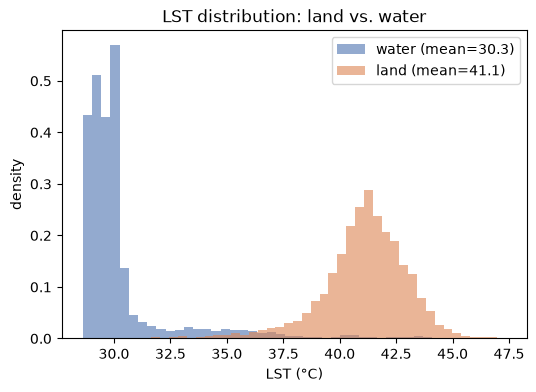

In [3]:
land_lst = land["lst"].dropna()
water_lst = water.loc[water["valid_lst"], "lst"].dropna()
combined_lst = df.loc[df["valid_lst"], "lst"].dropna()

print(f"land-only mean LST:      {land_lst.mean():.2f} degC  (n={len(land_lst)})")
print(f"water-only mean LST:     {water_lst.mean():.2f} degC  (n={len(water_lst)})")
print(f"combined (land+water):   {combined_lst.mean():.2f} degC  (n={len(combined_lst)})")

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(water_lst, bins=40, alpha=0.6, label=f"water (mean={water_lst.mean():.1f})", color="#4c72b0", density=True)
ax.hist(land_lst, bins=40, alpha=0.6, label=f"land (mean={land_lst.mean():.1f})", color="#dd8452", density=True)
ax.set_xlabel("LST (°C)")
ax.set_ylabel("density")
ax.set_title("LST distribution: land vs. water")
ax.legend()
plt.show()

**Key observation**: land-only mean LST ≈ 41.1°C vs. water-only ≈ 30.3°C — an ~11°C gap.
Computing `lst_z` (or any land statistic) over all pixels rather than land cells only would
badly bias the result toward the cooler sea-surface values, given ~47% of the AOI bbox is
ocean. This single number is the empirical justification for the whole `land_mask` convention
used from `preprocess.py` onward.

## Correlation heatmap (land cells)

            lst   ndvi   ndbi  built_up
lst       1.000 -0.486  0.724     0.356
ndvi     -0.486  1.000 -0.784    -0.014
ndbi      0.724 -0.784  1.000     0.378
built_up  0.356 -0.014  0.378     1.000


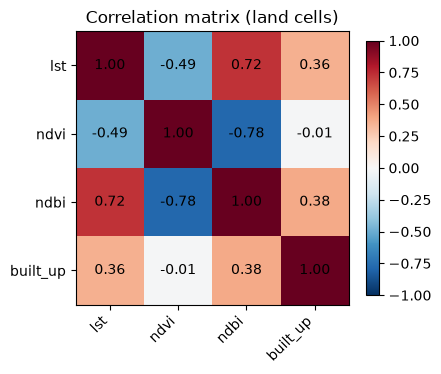

In [4]:
corr = land[["lst", "ndvi", "ndbi", "built_up"]].corr()
print(corr.round(3))

fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels(corr.index)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{corr.values[i,j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation matrix (land cells)")
fig.tight_layout()
plt.show()

**Key observation**: `ndvi` and `built_up` (GHSL) correlate at essentially zero
(r ≈ -0.01), despite `ndvi` and `ndbi` (also a built-up-style index, but derived from the same
Landsat composite as LST/NDVI) correlating strongly negatively (r ≈ -0.78). This isn't a bug —
GHSL is a different-year (2020), coarser-provenance product built from a different sensor/
methodology than NDBI (derived directly from the 2024 Landsat composite), so it's picking up a
different, noisier signal of "built-up-ness" than an index computed from the exact same
imagery as NDVI. Worth remembering before treating `built_up` and `ndbi` as interchangeable
built-up proxies.

## LST by land cover (preview)

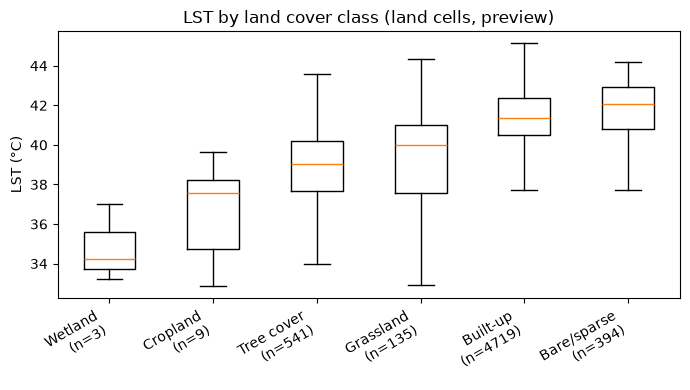

            count   mean   std
lulc_class                    
90.0            3  34.81  1.95
40.0            9  36.65  2.25
10.0          533  38.65  2.33
30.0          135  39.25  2.47
50.0         4703  41.38  1.56
60.0          394  41.51  2.07


In [5]:
WORLDCOVER_LABELS = {10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland",
                      50: "Built-up", 60: "Bare/sparse", 80: "Water", 90: "Wetland"}

groups = land.dropna(subset=["lulc_class"]).groupby("lulc_class")["lst"]
order = groups.mean().sort_values().index

fig, ax = plt.subplots(figsize=(7, 4))
data = [groups.get_group(cls).dropna().values for cls in order]
labels = [f"{WORLDCOVER_LABELS.get(int(c), int(c))}\n(n={len(groups.get_group(c))})" for c in order]
ax.boxplot(data, tick_labels=labels, showfliers=False)
ax.set_ylabel("LST (°C)")
ax.set_title("LST by land cover class (land cells, preview)")
plt.xticks(rotation=30, ha="right")
fig.tight_layout()
plt.show()

print(groups.agg(["count", "mean", "std"]).round(2).sort_values("mean"))

Built-up and bare/sparse classes run hottest, tree cover/wetland coolest — consistent with
expectations and with the hotspot analysis's cold-spot findings (the eastern wetland/park
cluster). `validation.py` computes the final version of this table with proper quartiles for
the paper figure; this is just a quick-look preview to confirm the pattern looks sane before
relying on it downstream.